# Extração de conhecimento — Pulsares (HTRU2) + Meteoritos (NASA)

Notebook de **EDA inicial**

| Passo | Onde aparece aqui |
|---|---|
| 1. Compreensão do problema / hipóteses | Seções "Hipóteses" de cada dataset |
| 2. Seleção dos dados | Carregamento + recortes |
| 3. Pré-processamento | Limpeza (nulos, duplicatas, valores inválidos) |
| 4. Transformação | Log de variáveis assimétricas, agrupamento de classes, prévia de PCA |

Posteriormente vamos caminhar para a modelagem e interpretação.

In [22]:
%pip install -q ucimlrepo

import re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RANDOM_STATE = 42

Note: you may need to restart the kernel to use updated packages.


---
# Parte A — Pulsares (HTRU2)

**Fonte:** UCI Machine Learning Repository, dataset 372 (HTRU2), Lyon et al. — candidatos a pulsar do *High Time Resolution Universe Survey (South)*.

Cada candidato tem **8 atributos contínuos** e um rótulo binário (1 = pulsar real, 0 = ruído/RFI):

- 4 estatísticas do **perfil de pulso integrado** (IP): média, desvio-padrão, curtose, assimetria
- 4 estatísticas da **curva DM-SNR** (dispersion measure × signal-to-noise): média, desvio-padrão, curtose, assimetria

## Passo 1 — Hipóteses
- **H1:** Pulsares reais têm perfil de pulso mais "pontiagudo" (curtose e assimetria do IP maiores) do que ruído.
- **H2:** Atributos do IP separam melhor as classes do que os da curva DM-SNR.
- **H3:** As classes são quase linearmente separáveis em poucas direções → modelos lineares (Logística, SVM linear) devem ir bem; kernels trariam ganho marginal.
- **H4:** Como só ~9% são pulsares, acurácia será enganosa — a métrica relevante é recall/AUC (perder um pulsar real é caro).

In [23]:
from ucimlrepo import fetch_ucirepo

htru2 = fetch_ucirepo(id=372)
X_p = htru2.data.features.copy()
y_p = htru2.data.targets.copy()

print("Nomes originais:", list(X_p.columns), "| alvo:", list(y_p.columns))

# nomes curtos e padronizados (ordem documentada pela UCI)
short = ["ip_mean", "ip_std", "ip_kurt", "ip_skew",
         "dm_mean", "dm_std", "dm_kurt", "dm_skew"]
assert X_p.shape[1] == 8
X_p = X_p.rename(columns={"Profile_mean": "ip_mean", "Profile_stdev": "ip_std",
    "Profile_skewness": "ip_skew", "Profile_kurtosis": "ip_kurt",
    "DM_mean": "dm_mean", "DM_stdev": "dm_std",
    "DM_skewness": "dm_skew", "DM_kurtosis": "dm_kurt"})[short]
pulsar = X_p.assign(is_pulsar=y_p.iloc[:, 0].astype(int))
pulsar.head()

Nomes originais: ['Profile_mean', 'Profile_stdev', 'Profile_skewness', 'Profile_kurtosis', 'DM_mean', 'DM_stdev', 'DM_skewness', 'DM_kurtosis'] | alvo: ['class']


,ip_mean,ip_std,ip_kurt,ip_skew,dm_mean,dm_std,dm_kurt,dm_skew,is_pulsar
0,140.562,55.684,-0.700,-0.235,3.200,19.110,74.242,7.976,0
1,102.508,58.882,-0.515,0.465,1.677,14.860,127.394,10.576,0
2,103.016,39.342,1.051,0.323,3.121,21.745,63.172,7.736,0
3,136.750,57.178,-0.636,-0.068,3.643,20.959,53.594,6.896,0
4,88.727,40.672,1.123,0.601,1.179,11.469,252.567,14.270,0


## Passo 3 — Qualidade dos dados
Esta seção se relaciona intimamente com a H4, evidenciando se existe a distorção da quantidade de amostras que se referem a pulsares comparando-se com ruído.

In [24]:
print("Shape:", pulsar.shape)
print("\nNulos por coluna:\n", pulsar.isna().sum())
print("\nLinhas duplicadas:", pulsar.duplicated().sum())

counts = pulsar["is_pulsar"].value_counts()
print("\nBalanceamento:\n", counts, "\n", (counts / len(pulsar)).round(3))

Shape: (17898, 9)

Nulos por coluna:
 ip_mean      0
ip_std       0
ip_kurt      0
ip_skew      0
dm_mean      0
dm_std       0
dm_kurt      0
dm_skew      0
is_pulsar    0
dtype: int64

Linhas duplicadas: 0

Balanceamento:
 is_pulsar
0    16259
1     1639
Name: count, dtype: int64 
 is_pulsar
0   0.908
1   0.092
Name: count, dtype: float64


### Curvas ROC e PR
**Como interpretar:**

  - AUC-ROC: 0,5 é aleatório e 1,0 é perfeito.
  - AUC-PR: compare com a prevalência (≈ 0,09), não com 0,5. Sob desbalanceamento, ela é a métrica mais honesta.
  
Coluna “direção”: o sinal “−” indica que valores menores do atributo apontam para pulsar, como acontece com ip_mean.

Prevalência de pulsares: 0.092
Acurácia do classificador trivial (sempre 0): 0.908  | recall = 0.000



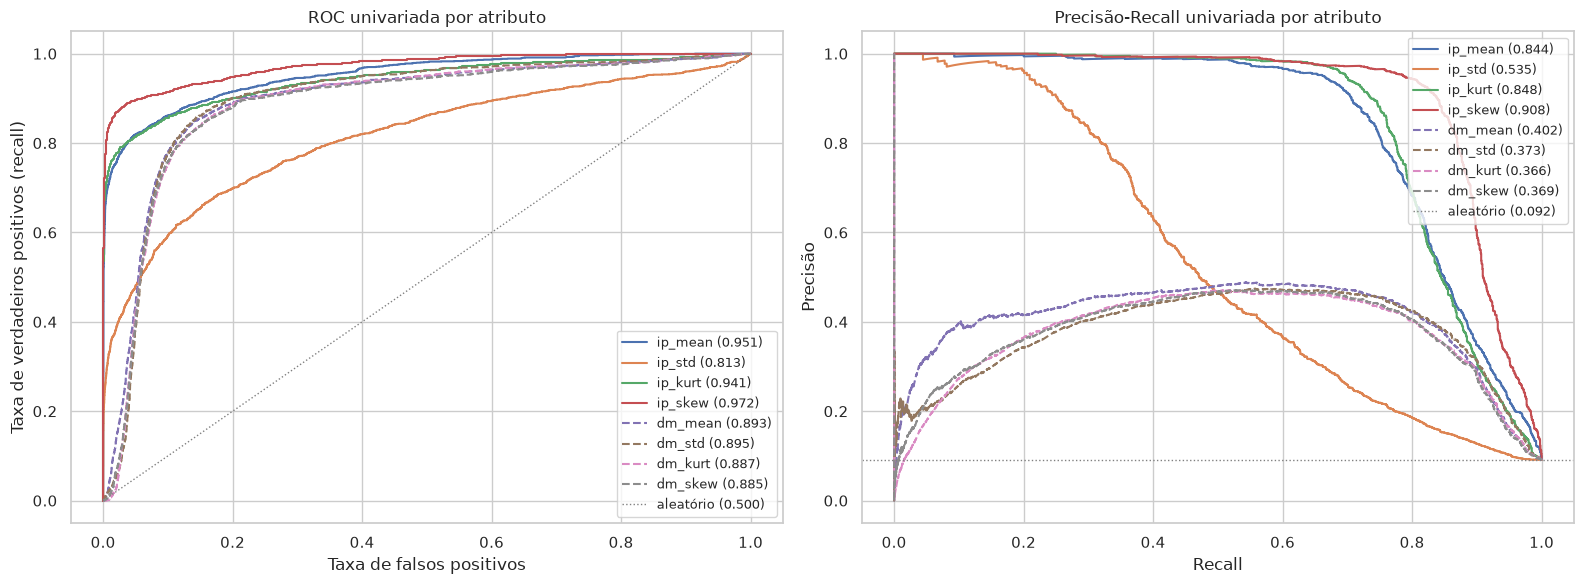

,atributo,bloco,direção,AUC_ROC,AUC_PR
0,ip_skew,IP,+,0.972,0.908
1,ip_mean,IP,−,0.951,0.844
2,ip_kurt,IP,+,0.941,0.848
3,dm_std,DM,+,0.895,0.373
4,dm_mean,DM,+,0.893,0.402
5,dm_kurt,DM,−,0.887,0.366
6,dm_skew,DM,−,0.885,0.369
7,ip_std,IP,−,0.813,0.535



Média por bloco (testa H2):


,AUC_ROC,AUC_PR
bloco,,
DM,0.890,0.378
IP,0.919,0.784


In [25]:
from sklearn.metrics import (roc_auc_score, roc_curve,
                             average_precision_score, precision_recall_curve)

features = ["ip_mean", "ip_std", "ip_kurt", "ip_skew",
            "dm_mean", "dm_std", "dm_kurt", "dm_skew"]

y = pulsar["is_pulsar"].values
prev = y.mean()

# baseline, sempre prever "ruído"
print(f"Prevalência de pulsares: {prev:.3f}")
print(f"Acurácia do classificador trivial (sempre 0): {1 - prev:.3f}  | recall = 0.000\n")

rows = []
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for col in features:
    x = pulsar[col].values
    sign = 1 if roc_auc_score(y, x) >= 0.5 else -1   # inverte atributos com associação negativa
    score = sign * x
    auc = roc_auc_score(y, score)
    ap = average_precision_score(y, score)
    rows.append({"atributo": col, "bloco": col[:2].upper(),
                 "direção": "+" if sign == 1 else "−", "AUC_ROC": auc, "AUC_PR": ap})

    fpr, tpr, _ = roc_curve(y, score)
    prec, rec, _ = precision_recall_curve(y, score)
    ls = "-" if col.startswith("ip") else "--"   # IP = linha cheia, DM = tracejada
    axes[0].plot(fpr, tpr, ls=ls, label=f"{col} ({auc:.3f})")
    axes[1].plot(rec, prec, ls=ls, label=f"{col} ({ap:.3f})")

axes[0].plot([0, 1], [0, 1], c="gray", lw=1, ls=":", label="aleatório (0.500)")
axes[0].set(xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos (recall)",
            title="ROC univariada por atributo")
axes[1].axhline(prev, c="gray", lw=1, ls=":", label=f"aleatório ({prev:.3f})")
axes[1].set(xlabel="Recall", ylabel="Precisão", title="Precisão-Recall univariada por atributo")
for ax in axes:
    ax.legend(fontsize=9, loc="lower right" if ax is axes[0] else "upper right")
plt.tight_layout(); plt.show()

auc_table = pd.DataFrame(rows).sort_values("AUC_ROC", ascending=False).reset_index(drop=True)
display(auc_table)
print("\nMédia por bloco (testa H2):")
display(auc_table.groupby("bloco")[["AUC_ROC", "AUC_PR"]].mean())

In [26]:
# estatísticas por classe — já testa H1 de forma descritiva
pulsar.groupby("is_pulsar").agg(["mean", "median", "std"]).T

is_pulsar            0      1
ip_mean mean   116.563 56.691
        median 117.258 54.297
        std     17.476 30.008
ip_std  mean    47.340 38.711
        median  47.486 37.341
        std      6.183  8.034
ip_kurt mean     0.381 15.554
        median   0.124 11.610
        std      1.028 13.997
ip_skew mean     0.210  3.131
        median   0.187  2.961
        std      0.335  1.873
dm_mean mean     8.863 49.826
        median   2.635 33.495
        std     24.411 45.288
dm_std  mean    23.288 56.469
        median  17.618 59.367
        std     16.651 19.731
dm_kurt mean   113.620 17.932
        median  90.675  2.585
        std    106.722 50.896
dm_skew mean     8.863  2.757
        median   8.760  1.918
        std      4.239  3.106

## Distribuições por classe

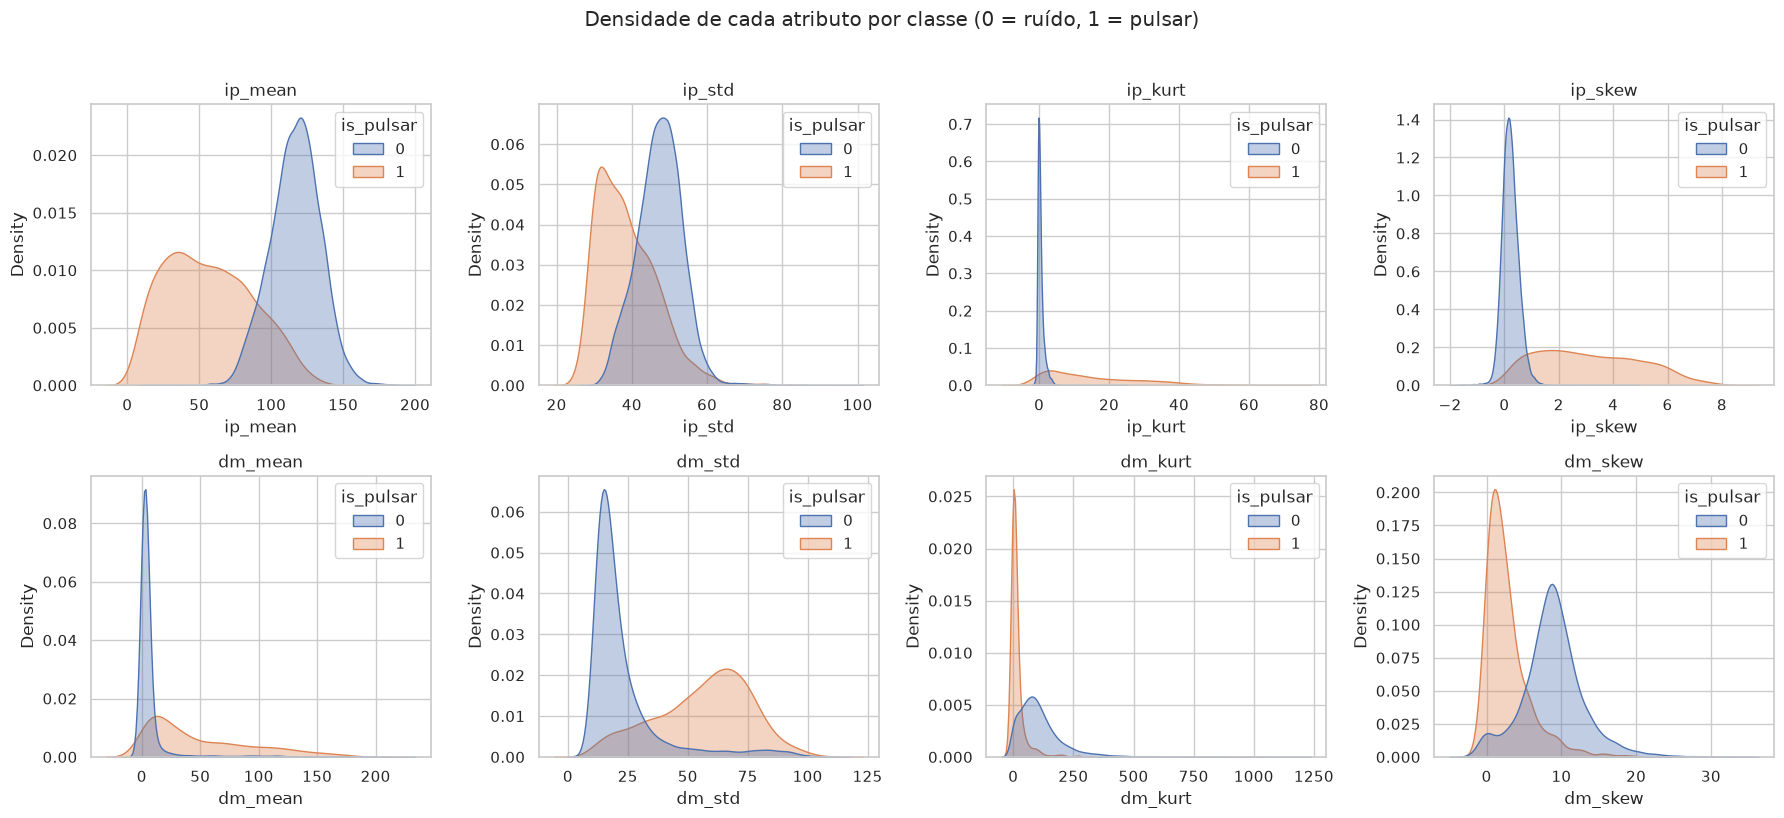

In [27]:
features = short
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), features):
    sns.kdeplot(data=pulsar, x=col, hue="is_pulsar", common_norm=False,
                fill=True, alpha=0.35, ax=ax)
    ax.set_title(col)
fig.suptitle("Densidade de cada atributo por classe (0 = ruído, 1 = pulsar)", y=1.02)
plt.tight_layout(); plt.show()

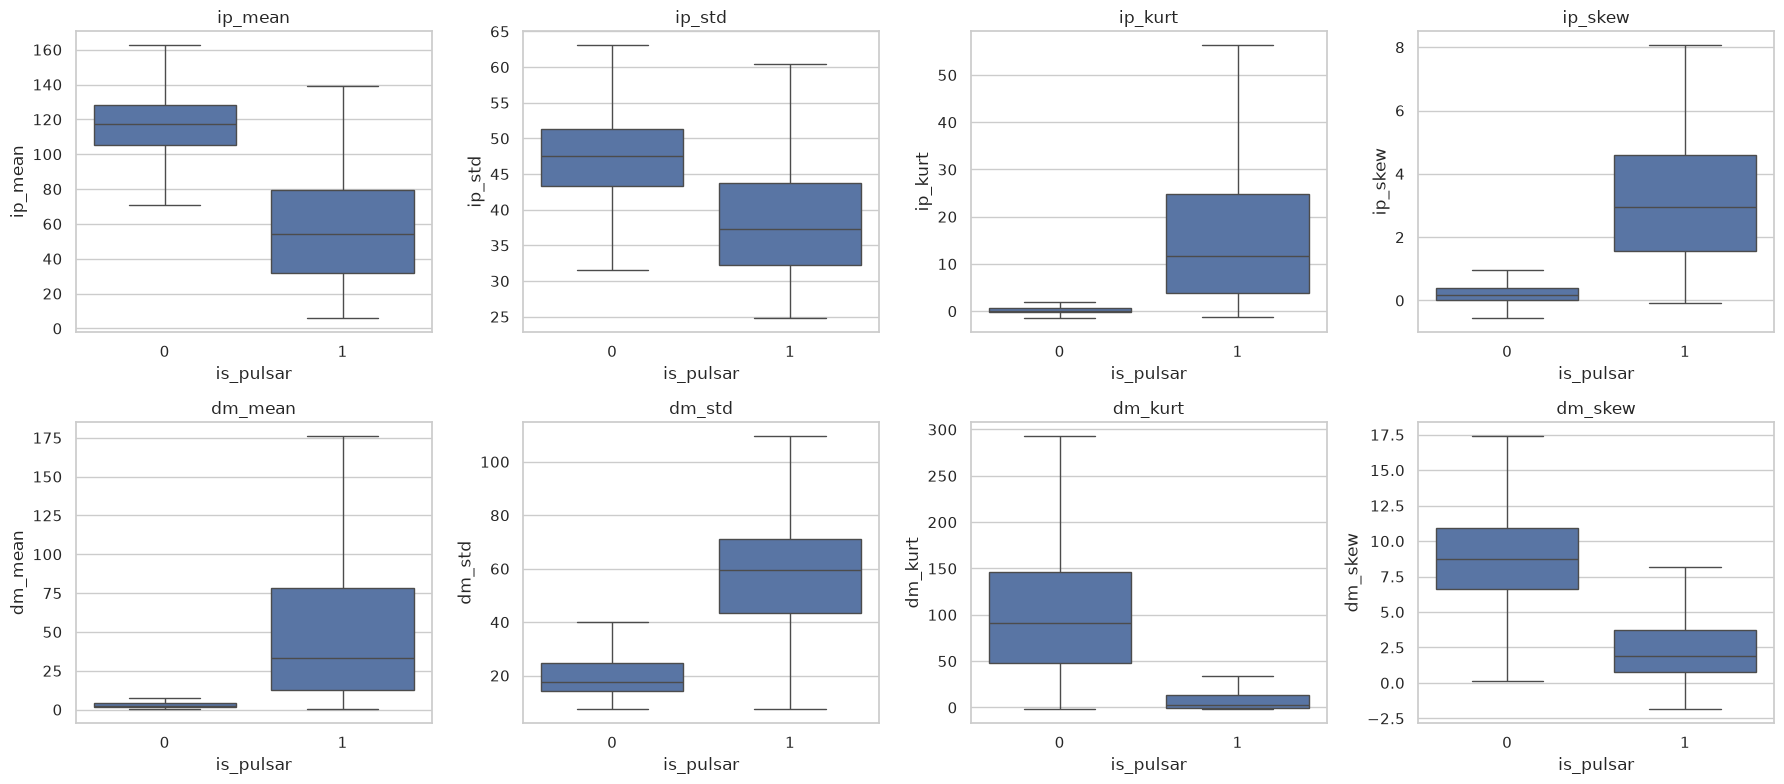

Assimetria (skew) de cada atributo:
ip_kurt    5.181
dm_mean    3.683
ip_skew    3.638
dm_kurt    2.735
dm_std     1.894
dm_skew    0.442
ip_std     0.127
ip_mean   -1.375
dtype: float64


In [28]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=pulsar, x="is_pulsar", y=col, ax=ax, showfliers=False)
    ax.set_title(col)
plt.tight_layout(); plt.show()

print("Assimetria (skew) de cada atributo:")
print(pulsar[features].skew().sort_values(ascending=False))

## Correlações
Correlação forte entre pares (ex.: curtose × assimetria) indica redundância, que é relevante para Naive Bayes (hipótese de independência condicional) e para regressão linear entre atributos.

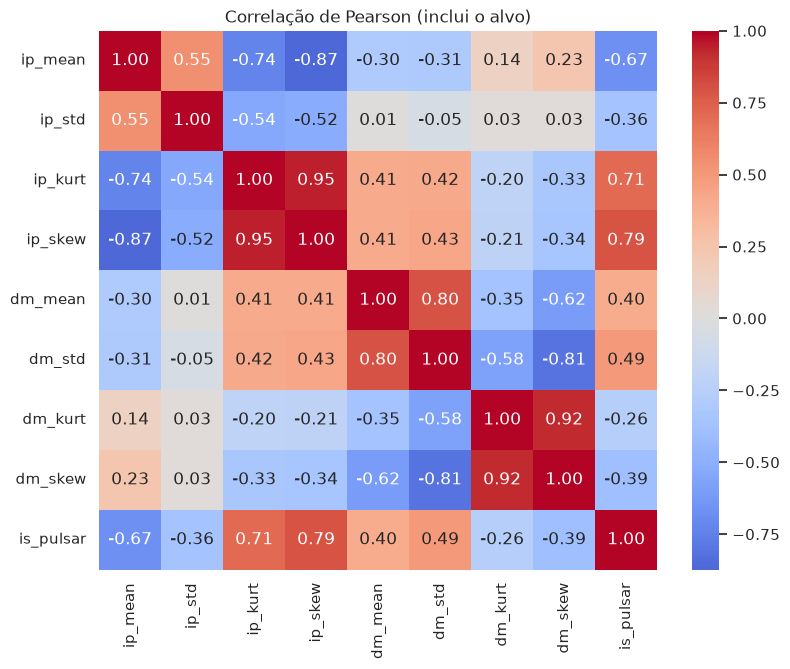

In [29]:
plt.figure(figsize=(9, 7))
sns.heatmap(pulsar.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação de Pearson (inclui o alvo)")
plt.show()

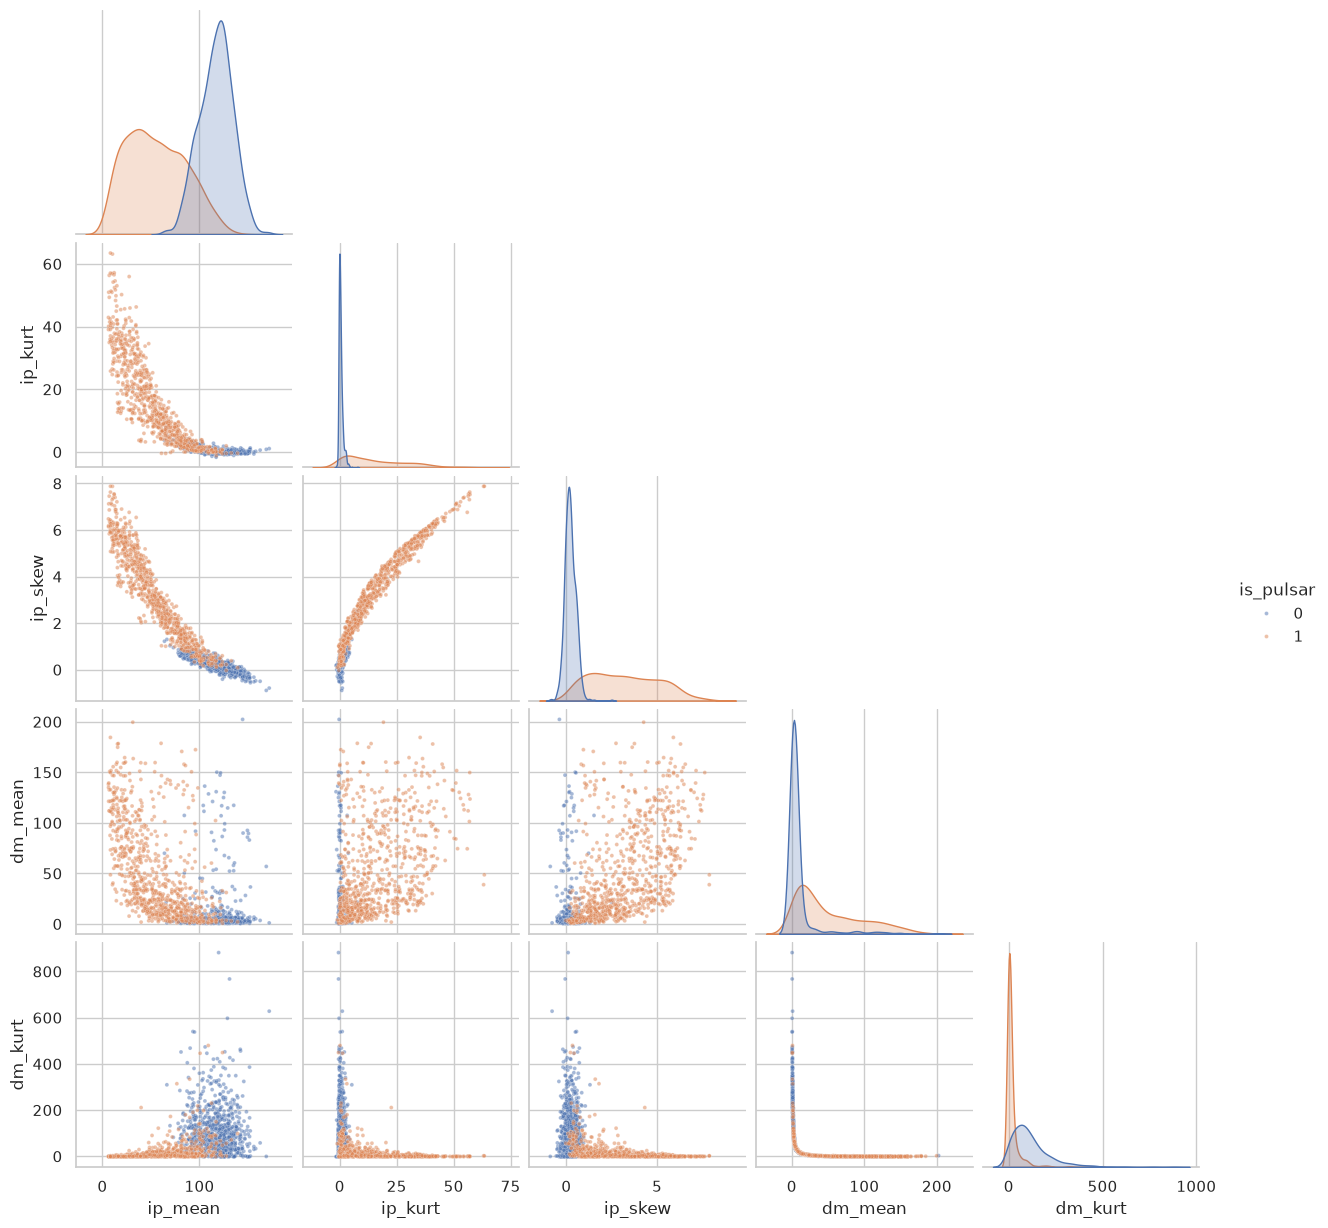

In [30]:
# pairplot em amostra estratificada
sample = pd.concat([g.sample(min(len(g), 800), random_state=RANDOM_STATE)
                    for _, g in pulsar.groupby("is_pulsar")])
sns.pairplot(sample, vars=["ip_mean", "ip_kurt", "ip_skew", "dm_mean", "dm_kurt"],
             hue="is_pulsar", plot_kws=dict(s=8, alpha=0.5), corner=True)
plt.show()

## Passo 4 — Prévia de PCA
Padronizamos e projetamos em 2D. Se as classes já aparecem separadas aqui, isso reforça H3.

Variância explicada por componente: [0.517 0.268 0.101 0.057 0.032 0.02  0.003 0.002]
Acumulada: [0.517 0.785 0.886 0.943 0.975 0.995 0.998 1.   ]


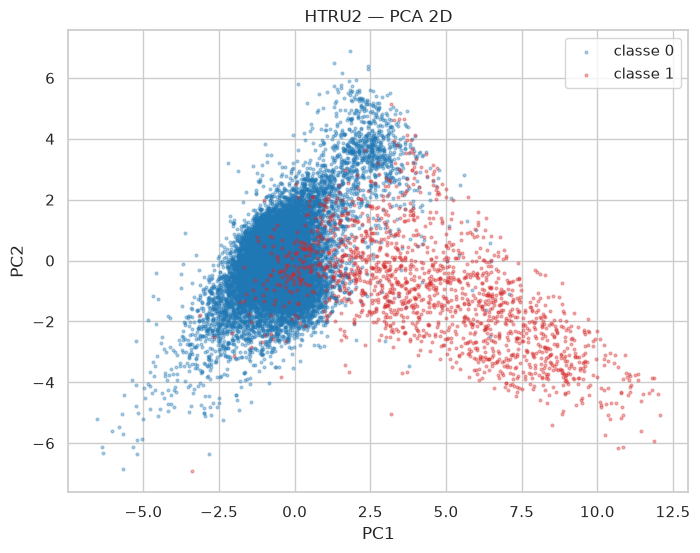

,PC1,PC2,PC3
ip_mean,-0.360,0.362,-0.013
ip_std,-0.212,0.430,0.436
ip_kurt,0.401,-0.306,0.083
ip_skew,0.416,-0.318,0.092
dm_mean,0.346,0.248,0.570
dm_std,0.386,0.317,0.234
dm_kurt,-0.292,-0.398,0.582
dm_skew,-0.370,-0.411,0.273


In [31]:
Xs = StandardScaler().fit_transform(pulsar[features])
pca = PCA().fit(Xs)
print("Variância explicada por componente:", pca.explained_variance_ratio_.round(3))
print("Acumulada:", pca.explained_variance_ratio_.cumsum().round(3))

Z = pca.transform(Xs)[:, :2]
plt.figure(figsize=(8, 6))
for cls, color in [(0, "tab:blue"), (1, "tab:red")]:
    m = pulsar["is_pulsar"].values == cls
    plt.scatter(Z[m, 0], Z[m, 1], s=4, alpha=0.35, c=color, label=f"classe {cls}")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(); plt.title("HTRU2 — PCA 2D")
plt.show()

loadings = pd.DataFrame(pca.components_[:3].T, index=features, columns=["PC1", "PC2", "PC3"])
loadings

### Anotações para o relatório
- H1: H1 confirmada: pulsares apresentam curtose e assimetria do perfil integrado muito maiores que o ruído (mediana da assimetria ≈ 3,0 vs. ≈ 0,19; da curtose ≈ 11,6 vs. ≈ 0,12). O ruído se concentra em valores próximos de zero, compatíveis com um sinal sem pico, enquanto os pulsares ocupam uma faixa ampla, refletindo a diversidade de seus perfis.

- H2: Os dados, especialmente a matriz de correlação, apoiam a hipótese 2. Os atributos do perfil integrado têm correlação com a classe consideravelmente maior que os da curva DM-SNR (|r| médio ≈ 0,63 vs. ≈ 0,39), e ip_kurt é o atributo isolado mais informativo (r = 0,79). Como Pearson captura apenas relações lineares e os atributos DM têm caudas longas, a confirmação depende da comparação de modelos treinados separadamente com cada bloco. A matriz também revela forte redundância dentro de cada bloco (curtose × assimetria com r > 0,9), relevante para o Naive Bayes e para a interpretação dos coeficientes.
- H3: Podemos constatar parcialmente a hipótese, a primeira componente principal, obtida sem uso dos rótulos e responsável por 51,7% da variância, já separa visualmente a maior parte dos pulsares do ruído, o que indica uma fronteira aproximadamente linear. Persiste, porém, uma região de sobreposição em que alguns pulsares se confundem com ruído. Esses casos devem limitar o recall de qualquer classificador, e o ganho de modelos não lineares sobre os lineares será o teste definitivo da hipótese.
- H4: O balanceamento sustenta a hipótese; pulsares representam ≈ 9,2% dos candidatos, de modo que um classificador trivial obteria ≈ 90,8% de acurácia sem detectar nenhum pulsar. Os gráficos de pares, feitos com amostra balanceada apenas para visualização, mostram pulsares imersos na região dominada por ruído. No conjunto real, esses casos tendem a virar falsos negativos sem afetar a acurácia, o que justifica priorizar recall, AUC-ROC e a curva precisão-recall na avaliação.

- Observações de pré-processamento (escala, caudas longas, correlações):

  ○ Qualidade: não há valores ausentes nem duplicatas. Nenhuma linha foi removida.

  ○ Escala: os atributos têm ordens de grandeza muito diferentes (ip_mean ≈ 100, dm_mean até ≈ 200, ip_kurt entre 0 e 8). Modelos baseados em distância ou margem (KNN, SVM, MLP) e a Logística regularizada exigem padronização. O StandardScaler será ajustado só no treino, dentro de um Pipeline. Árvores e ensembles não precisam disso.

  ○ Caudas longas: ip_skew, ip_kurt, dm_mean e dm_std têm forte assimetria à direita. O ruído se concentra perto de zero e os pulsares ocupam a cauda. Como há valores negativos (curtose e assimetria podem ser < 0), o log direto não se aplica. A alternativa é a transformação Yeo-Johnson (PowerTransformer), a ser testada principalmente para Naive Bayes Gaussiano e para a fronteira gaussiana, que pressupõem normalidade.

  ○ Outliers: não serão removidos. Na classe 1, os valores extremos são o sinal. Removê-los apagaria justamente os pulsares mais evidentes e pioraria o desbalanceamento.

  ○ Correlações: os atributos formam dois blocos muito redundantes (ip_kurt–ip_skew r = 0,95; dm_kurt–dm_skew r = 0,92), com correlação moderada entre blocos (~0,4). Isso implica violação da independência condicional no Naive Bayes e instabilidade dos coeficientes da Logística. Várias relações são não lineares (ip_kurt × ip_skew é curva, dm_mean × dm_kurt é hiperbólica), então o r de Pearson subestima a dependência real.

  ○ Desbalanceamento: a prevalência é de 9,2%. A divisão treino/teste e a validação cruzada serão estratificadas, e a avaliação vai priorizar AUC-ROC, AUC-PR e recall em vez da acurácia.

  > **Atenção para a modelagem:** o `StandardScaler` acima foi ajustado no dataset inteiro só para visualização. Na modelagem, ajuste-o **apenas no treino** (use `Pipeline`) para evitar vazamento.

---
# Parte B — Meteoritos (NASA / The Meteoritical Society)

**Fonte:** NASA Open Data Portal — *Meteorite Landings* (~45 mil registros).

Atributos: nome, id, `nametype` (valid/relict), `recclass` (classe mineralógica), massa (g), `fall` (Fell = visto caindo / Found = encontrado depois), ano, latitude, longitude.

## Passo 1 — Hipóteses
- **H1 (viés de observação):** a maioria esmagadora dos meteoritos é *Found*; os *Fell* se concentram em regiões habitadas e em anos recentes.
- **H2 (Antártida):** expedições na Antártida produzem uma enorme massa de *Found* pequenos — isso deve aparecer como um cluster em latitudes < −60°.
- **H3 (massa):** meteoritos vistos caindo tendem a ser mais massivos (um bólido grande chama atenção), enquanto encontrados incluem muitos fragmentos minúsculos.
- **H4 (composição):** meteoritos metálicos (*Iron*) são super-representados entre os *Found*, por resistirem à erosão e serem fáceis de identificar.

In [32]:
# CSV em docs/ (local) ou upload manual (Colab).
# Fonte: https://data.nasa.gov/dataset/meteorite-landings
cands = sorted(glob.glob("Meteorite_Landings*.csv") + glob.glob("docs/Meteorite_Landings.csv"))
if not cands:
    from google.colab import files
    files.upload()
    cands = sorted(glob.glob("Meteorite_Landings*.csv"))
meteor_raw = pd.read_csv(cands[0])
print(meteor_raw.shape)
print(list(meteor_raw.columns))
meteor_raw.head()

(45716, 10)
['name', 'id', 'nametype', 'recclass', 'mass (g)', 'fall', 'year', 'reclat', 'reclong', 'GeoLocation']


,name,id,nametype,recclass,mass (g),fall,year,reclat,reclong,GeoLocation
0,Aachen,1,Valid,L5,21.000,Fell,"1,880.000",50.775,6.083,"(50.775, 6.08333)"
1,Aarhus,2,Valid,H6,720.000,Fell,"1,951.000",56.183,10.233,"(56.18333, 10.23333)"
2,Abee,6,Valid,EH4,"107,000.000",Fell,"1,952.000",54.217,-113.000,"(54.21667, -113.0)"
3,Acapulco,10,Valid,Acapulcoite,"1,914.000",Fell,"1,976.000",16.883,-99.900,"(16.88333, -99.9)"
4,Achiras,370,Valid,L6,780.000,Fell,"1,902.000",-33.167,-64.950,"(-33.16667, -64.95)"


In [33]:
meteor = meteor_raw.rename(columns={"mass (g)": "mass_g", "reclat": "lat", "reclong": "lon"})
meteor.columns = meteor.columns.str.lower()
# o ano pode vir como '1880', '1880.0' ou '01/01/1880 12:00:00 AM'
meteor["year"] = pd.to_numeric(meteor["year"].astype(str).str.extract(r"(\d{4})")[0], errors="coerce")
meteor.dtypes

name               str
id               int64
nametype           str
recclass           str
mass_g         float64
fall               str
year           float64
lat            float64
lon            float64
geolocation        str
dtype: object

## Passo 3 — Qualidade dos dados

In [34]:
print("Nulos:\n", meteor.isna().sum())
print("\nDuplicatas por id:", meteor["id"].duplicated().sum())
print("\nnametype:\n", meteor["nametype"].value_counts())
print("\nfall:\n", meteor["fall"].value_counts())

print("\nCoordenadas exatamente (0,0) — provável placeholder de 'desconhecido':",
      ((meteor["lat"] == 0) & (meteor["lon"] == 0)).sum())
print("Anos fora de [860, 2026]:", ((meteor["year"] < 860) | (meteor["year"] > 2026)).sum())
print("Massa == 0:", (meteor["mass_g"] == 0).sum())

Nulos:
 name              0
id                0
nametype          0
recclass          0
mass_g          131
fall              0
year            293
lat            7315
lon            7315
geolocation    7315
dtype: int64

Duplicatas por id: 0

nametype:
 nametype
Valid     45641
Relict       75
Name: count, dtype: int64

fall:
 fall
Found    44609
Fell      1107
Name: count, dtype: int64

Coordenadas exatamente (0,0) — provável placeholder de 'desconhecido': 6214
Anos fora de [860, 2026]: 1
Massa == 0: 19


In [35]:
CURRENT_YEAR = 2026
clean = meteor.copy()

# 1. só meteoritos 'valid'
clean = clean[clean["nametype"] == "Valid"]

# 2. coordenadas (0,0) viram ausentes
zero = (clean["lat"] == 0) & (clean["lon"] == 0)
clean.loc[zero, ["lat", "lon"]] = np.nan

# 3. anos impossíveis viram ausentes
clean.loc[(clean["year"] < 860) | (clean["year"] > CURRENT_YEAR), "year"] = np.nan

# 4. massa não positiva vira ausente; criamos log10 da massa (por se tratar de uma distribuição extremamente assimétrica)
clean.loc[clean["mass_g"] <= 0, "mass_g"] = np.nan
clean["log_mass"] = np.log10(clean["mass_g"])

clean["fell"] = (clean["fall"] == "Fell").astype(int)
print("Antes:", len(meteor), "| depois:", len(clean))
clean[["mass_g", "log_mass", "year", "lat", "lon"]].describe()

Antes: 45716 | depois: 45641


,mass_g,log_mass,year,lat,lon
count,"45,558.000","45,558.000","45,348.000","32,117.000","32,117.000"
mean,"13,285.948",1.636,"1,991.862",-46.890,72.977
std,"575,159.148",1.093,23.973,46.857,83.111
min,0.010,-2.000,"1,399.000",-87.367,-165.433
25%,7.200,0.857,"1,987.000",-79.683,26.000
50%,32.700,1.515,"1,998.000",-72.000,56.671
75%,202.900,2.307,"2,003.000",18.453,159.388
max,"60,000,000.000",7.778,"2,013.000",81.167,354.473


## Passo 4 — Agrupando `recclass`
`recclass` tem centenas de valores distintos — inviável como está para árvores ou one-hot. Agrupamos em famílias mineralógicas amplas (assim, simplificamos a regra, o que deve ser documentado no relatório posteriormente)

In [36]:
print("Classes distintas:", clean["recclass"].nunique())

def class_group(c):
    c = str(c)
    if re.match(r"^(H|L|LL|H/L|L/LL|OC)(?![a-z])", c):
        return "Condrito ordinário"
    if re.match(r"^C(I|M|O|V|K|R|H|B)?(?![a-z])", c):
        return "Condrito carbonáceo"
    if re.match(r"^E(H|L)?(?![a-z])", c):
        return "Condrito enstatita"
    if re.match(r"^(R|K)(?![a-z])", c):
        return "Outros condritos (R, K)"
    if c.startswith("Iron"):
        return "Ferroso (Iron)"
    if c.startswith(("Pallasite", "Mesosiderite")):
        return "Ferro-rochoso"
    if c.startswith(("Eucrite", "Howardite", "Diogenite", "Ureilite", "Aubrite", "Angrite",
                     "Acapulcoite", "Lodranite", "Winonaite", "Brachinite", "Martian",
                     "Lunar", "Shergottite", "Nakhlite", "Chassignite", "Achondrite")):
        return "Acondrito"
    return "Outros/não classificado"

clean["class_group"] = clean["recclass"].map(class_group)

Classes distintas: 461


In [37]:
# conferência: quais recclass caíram em 'Outros'?
clean.loc[clean["class_group"] == "Outros/não classificado", "recclass"].value_counts().head(20)

recclass
Stone-uncl             50
Chondrite-ung          15
Unknown                 7
Enst achon              3
Enst achon-ung          3
Impact melt breccia     1
Stone-ung               1
Name: count, dtype: int64

## Distribuições e relações com `fall`

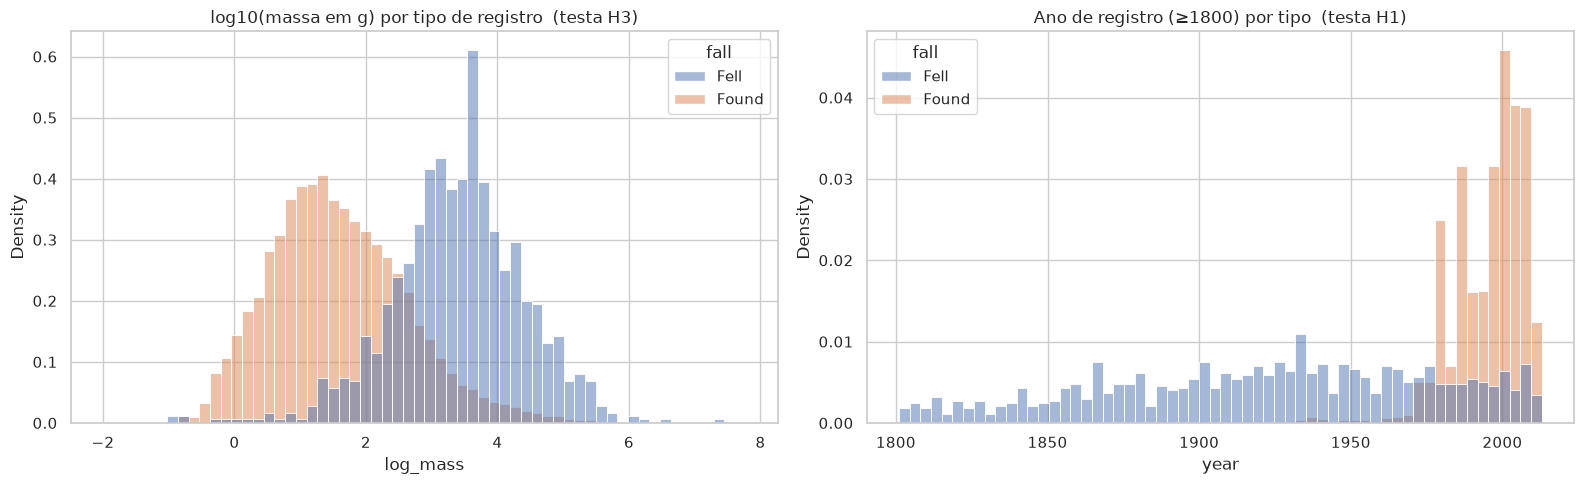

fall                Fell      Found
log_mass count 1,075.000 44,483.000
         mean      3.398      1.593
         std       1.006      1.059
         min      -1.000     -2.000
         25%       2.836      0.844
         50%       3.447      1.486
         75%       4.019      2.252
         max       7.362      7.778
year     count 1,105.000 44,243.000
         mean  1,913.084  1,993.830
         std      71.737     17.371
         min   1,399.000  1,575.000
         25%   1,875.000  1,988.000
         50%   1,924.000  1,998.000
         75%   1,964.000  2,003.000
         max   2,013.000  2,013.000

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(data=clean, x="log_mass", hue="fall", stat="density",
             common_norm=False, bins=60, ax=axes[0])
axes[0].set_title("log10(massa em g) por tipo de registro  (testa H3)")

sns.histplot(data=clean[clean["year"] >= 1800], x="year", hue="fall",
             stat="density", common_norm=False, bins=60, ax=axes[1])
axes[1].set_title("Ano de registro (≥1800) por tipo  (testa H1)")
plt.tight_layout(); plt.show()

clean.groupby("fall")[["log_mass", "year"]].describe().T

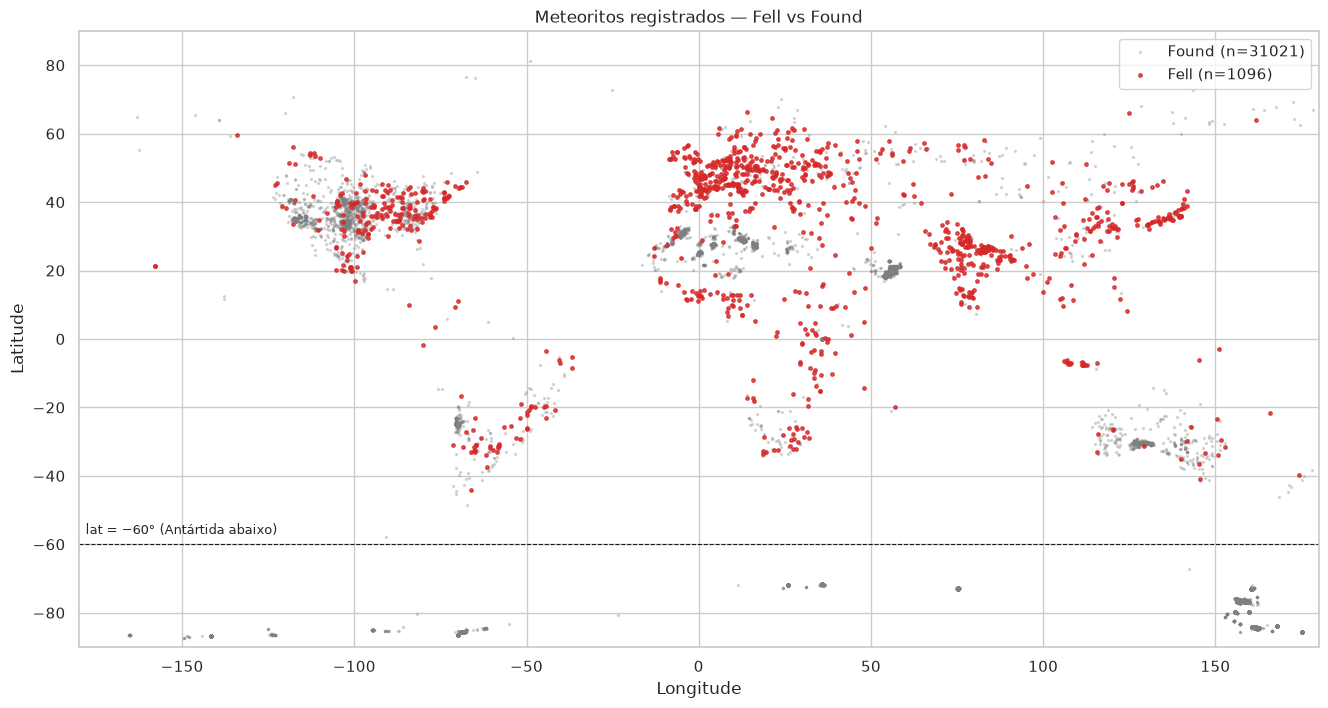

fall,Fell,Found,All
antarctica,,,
False,1096,8925,10021
True,0,22096,22096
All,1096,31021,32117


In [39]:
# mapa simples, testa H1 e H2
geo = clean.dropna(subset=["lat", "lon"]).copy()
plt.figure(figsize=(16, 8))
for label, color, size, alpha in [("Found", "tab:gray", 2, 0.25), ("Fell", "tab:red", 6, 0.8)]:
    g = geo[geo["fall"] == label]
    plt.scatter(g["lon"], g["lat"], s=size, c=color, alpha=alpha, label=f"{label} (n={len(g)})")
plt.axhline(-60, ls="--", c="k", lw=0.8)
plt.text(-178, -57, "lat = −60° (Antártida abaixo)", fontsize=9)
plt.xlim(-180, 180); plt.ylim(-90, 90)
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.legend()
plt.title("Meteoritos registrados — Fell vs Found")
plt.show()

geo["antarctica"] = geo["lat"] < -60
pd.crosstab(geo["antarctica"], geo["fall"], margins=True)

fall,Fell,Found
class_group,,
Acondrito,0.078,0.046
Condrito carbonáceo,0.040,0.035
Condrito enstatita,0.015,0.012
Condrito ordinário,0.773,0.875
Ferro-rochoso,0.010,0.006
Ferroso (Iron),0.044,0.023
"Outros condritos (R, K)",0.002,0.003
Outros/não classificado,0.038,0.001


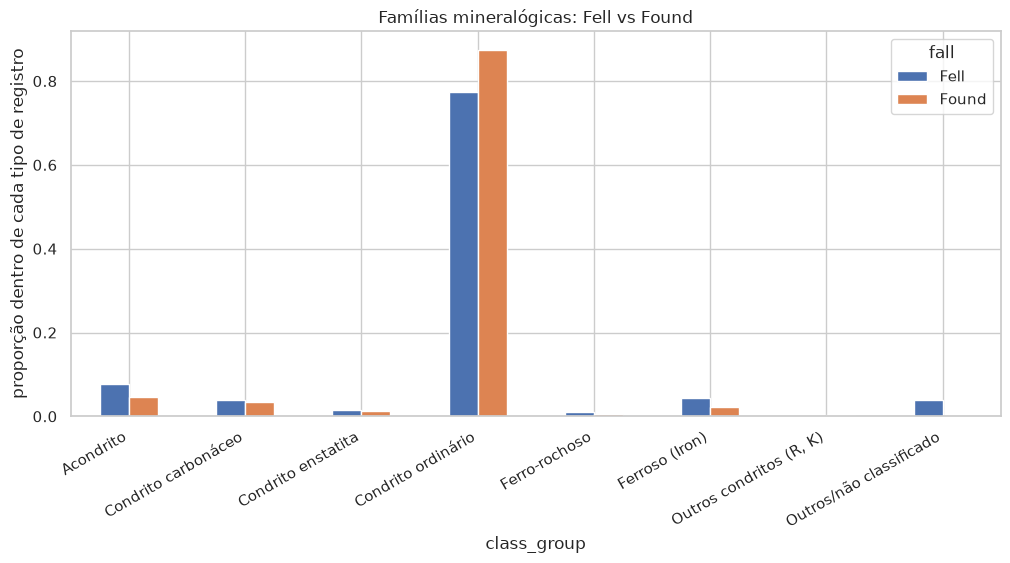

In [40]:
# composição × tipo de registro (testa H4) — proporções por linha
ct = pd.crosstab(clean["class_group"], clean["fall"], normalize="columns").round(3)
display(ct)

ct.plot(kind="bar", figsize=(12, 5))
plt.ylabel("proporção dentro de cada tipo de registro")
plt.title("Famílias mineralógicas: Fell vs Found")
plt.xticks(rotation=30, ha="right"); plt.show()

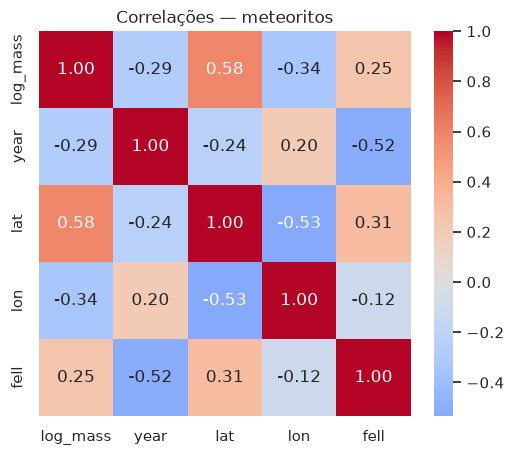

In [41]:
# correlação entre os atributos contínuos (base para a regressão linear)
num = clean[["log_mass", "year", "lat", "lon", "fell"]]
plt.figure(figsize=(6, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlações — meteoritos")
plt.show()

### Anotações para o relatório
- H1: (componente espacial) - **confirmada**: apenas 3,4% dos meteoritos georreferenciados foram vistos caindo, e esses se concentram em regiões densamente povoadas (Europa, Índia, leste da Ásia, leste dos EUA). Os encontrados posteriormente concentram-se em desertos quentes, onde o clima preserva o material e o contraste com o solo facilita a identificação. Ambos os registros refletem condições de observação, não a distribuição real de quedas.
  
  (componente temporal) - **refutada**: contrariando a hipótese inicial, as quedas observadas são em média mais antigas (r = −0,52 entre ano e Fell). Antes do século XX, meteoritos eram conhecidos quase só por quedas testemunhadas; as campanhas sistemáticas de busca na Antártida e em desertos, a partir de 1969, geraram dezenas de milhares de registros Found recentes. O viés de observação existe, mas opera no sentido oposto ao previsto no tempo.
- H2:Os dados confirmam a hipótese 2: 22.096 meteoritos (69% do total georreferenciado) estão abaixo de −60°, todos do tipo Found e nenhum Fell. Como a latitude antártica determina o rótulo de forma trivial, a Antártida foi excluída da modelagem de fell e analisada separadamente.
- H3: apoiada, meteoritos vistos caindo têm massa maior (r = 0,25 entre log da massa e Fell). Como a massa se correlaciona fortemente com a latitude (r = 0,58), efeito dos fragmentos antárticos, a hipótese foi reavaliada excluindo a Antártida.

- H4: Ao analisar globalmente, não confirmamos a hipótese; meteoritos metálicos representam ≈ 4,5% das quedas observadas e apenas ≈ 2,3% dos encontrados, o oposto do esperado. A hipótese é de que a coleta antártica, responsável por 71% dos Found e dominada por condritos ordinários, dilui a proporção de metálicos. A comparação restrita a regiões fora da Antártida testa esse efeito de confusão.

### Próximos passos (passo 5)
**Pulsares** (8 contínuos → binário): Logística, Naive Bayes Gaussiano, fronteira gaussiana, KNN, SVM (linear e RBF), MLP; comparar por AUC/ROC, recall e matriz de confusão, com `Pipeline` + validação cruzada estratificada. Regressão linear entre atributos (ex.: `ip_skew ~ ip_kurt`) para entender redundância.

**Meteoritos** (misto): classificar `fell` a partir de massa, ano, latitude e família (Árvore, Random Forest, AdaBoost, Logística), lidando com o desbalanceamento extremo; árvore de decisão sobre atributos categóricos (família, hemisfério, Antártida, faixa de época) para extrair regras legíveis. Discutir no passo 6 que o modelo aprende **onde e quando havia gente olhando**, não física do meteorito.